# Aerofit Treadmill Buyers: Customer Profiling with Descriptive Statistics & Probability

**Author:** Guntuku Hariprasad &nbsp;|&nbsp; **Program:** Scaler, Data Science & ML &nbsp;|&nbsp; **Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, SciPy

---

### Executive summary

| | KP281 (Entry, \$1,500) | KP481 (Mid, \$1,750) | KP781 (Advanced, \$2,500) |
|---|---|---|---|
| Share of buyers | **44.4%** | **33.3%** | **22.2%** |
| Share of revenue | 36.9% | 32.3% | 30.8% |
| Typical income | ~\$46.6K | ~\$49.5K | **~\$76.6K** |
| Planned use / week | 3 days | 3 days | **5 days** |
| Self-rated fitness | 3 / 5 | 3 / 5 | **5 / 5** |
| Expected miles / week | 85 | 85 | **160** |
| Gender split (M : F) | 50 : 50 | 52 : 48 | **82.5 : 17.5** |

**Key takeaways**
1. **Income, fitness, usage and miles separate the buyers; age and marital status hardly do.** KP781 buyers are a distinct group: higher earners (every buyer above \$80K chose it), very fit, and heavy users.
2. **KP281 and KP481 buyers look almost the same**, so the \$250 gap is the deciding factor. KP481 needs a clearer reason to exist (sharper positioning or bundling).
3. **P(KP781 | Male) = 31.7% vs P(KP781 | Female) = 9.2%.** Women are under-served at the premium end, which is a growth opportunity.
4. A customer who plans to run **5+ days a week** or rates fitness **5/5** buys the KP781 **70 to 100%** of the time, which gives sales staff a simple qualifying rule.

### Contents
1. Problem statement & basic metrics
2. Non-graphical analysis: value counts & unique values
3. Missing values & outlier detection
4. Visual analysis: univariate
5. Visual analysis: bivariate (effect of features on product purchased)
6. Correlation: heatmap & pairplot
7. Probability: marginal, joint & conditional (contingency tables)
8. Customer profiling for each product
9. Business insights
10. Recommendations

## 1. Problem statement & basic metrics

**Business problem.** Aerofit's market research team wants to know **who buys each treadmill** (KP281, KP481, KP781) so that it can **recommend the right model to new customers**. We investigate whether the products differ in customer characteristics (age, gender, education, marital status, planned usage, income, fitness, expected miles).

**What we will deliver**
* A descriptive profile of the buyer for every product (tables and charts).
* Two-way contingency tables for each product with **marginal, joint and conditional probabilities**, and what each means for the business.
* Simple, actionable recommendations.

**Data.** 180 customers who bought an Aerofit treadmill in the prior three months.

| Feature | Description |
|---|---|
| Product | KP281, KP481 or KP781 |
| Age | In years |
| Gender | Male / Female |
| Education | In years |
| MaritalStatus | Single or Partnered |
| Usage | Average number of times the customer plans to use the treadmill each week |
| Income | Annual income (in \$) |
| Fitness | Self-rated fitness, 1 (poor shape) to 5 (excellent shape) |
| Miles | Average number of miles the customer expects to walk/run each week |

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 2)
pd.set_option("display.width", 120)

# ---- Consistent visual identity: each product always has the same colour ----
PRODUCTS = ["KP281", "KP481", "KP781"]
PROD_PAL = dict(zip(PRODUCTS, ["#2a78d6", "#eb6834", "#1baf7a"]))   # blue / orange / aqua
BIN_PAL = ["#6250d6", "#eda100"]                                     # for 2-level attributes
PRICE = {"KP281": 1500, "KP481": 1750, "KP781": 2500}

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 90, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "axes.edgecolor": "#9a9893", "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})

IMG_DIR = Path("../images"); IMG_DIR.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(IMG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")

In [2]:
# Load the data (local copy in the repo; falls back to the original Scaler link)
LOCAL = Path("../data/aerofit_treadmill.csv")
URL = ("https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/125/"
       "original/aerofit_treadmill.csv?1639992749")
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
df.head()

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,KP281,18,Male,14,Single,3,4,29562,112
1,KP281,19,Male,15,Single,2,3,31836,75
2,KP281,19,Female,14,Partnered,4,3,30699,66
3,KP281,19,Male,12,Single,3,3,32973,85
4,KP281,20,Male,13,Partnered,4,2,35247,47


In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (180, 9)

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Product        180 non-null    str  
 1   Age            180 non-null    int64
 2   Gender         180 non-null    str  
 3   Education      180 non-null    int64
 4   MaritalStatus  180 non-null    str  
 5   Usage          180 non-null    int64
 6   Fitness        180 non-null    int64
 7   Income         180 non-null    int64
 8   Miles          180 non-null    int64
dtypes: int64(6), str(3)
memory usage: 12.8 KB


**Observations**
* 180 rows, 9 columns. Every row is one purchase.
* 3 text columns (`Product`, `Gender`, `MaritalStatus`) and 6 integer columns.
* No column has null values (180 non-null everywhere).
* `Usage`, `Fitness` and `Education` are stored as integers, but they are really **ordinal** (a small set of ordered levels), so we treat them as both numbers (for summaries and correlation) and categories (for counts and probabilities).

In [4]:
# Convert the text attributes to the memory-efficient 'category' dtype
cat_cols = ["Product", "Gender", "MaritalStatus"]
num_cols = ["Age", "Education", "Usage", "Fitness", "Income", "Miles"]
mem_before = df.memory_usage(deep=True).sum()
for c in cat_cols:
    df[c] = df[c].astype("category")
df["Product"] = df["Product"].cat.reorder_categories(PRODUCTS, ordered=True)
print(f"Memory: {mem_before/1024:.1f} KB -> {df.memory_usage(deep=True).sum()/1024:.1f} KB")
df.dtypes

Memory: 37.5 KB -> 9.5 KB


Product          category
Age                 int64
Gender           category
Education           int64
MaritalStatus    category
Usage               int64
Fitness             int64
Income              int64
Miles               int64
dtype: object

In [5]:
# Statistical summary of the numeric attributes (with range, IQR and mean-median gap)
summary = df[num_cols].describe().T
summary["range"] = summary["max"] - summary["min"]
summary["IQR"] = summary["75%"] - summary["25%"]
summary["mean - median"] = summary["mean"] - summary["50%"]
summary["skew"] = df[num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,range,IQR,mean - median,skew
Age,180.0,28.79,6.94,18.0,24.00,26.0,33.00,50.0,32.0,9.00,2.79,0.98
Education,180.0,15.57,1.62,12.0,14.00,16.0,16.00,21.0,9.0,2.00,-0.43,0.62
Usage,180.0,3.46,1.08,2.0,3.00,3.0,4.00,7.0,5.0,1.00,0.46,0.74
Fitness,180.0,3.31,0.96,1.0,3.00,3.0,4.00,5.0,4.0,1.00,0.31,0.45
Income,180.0,53719.58,16506.68,29562.0,44058.75,50596.5,58668.00,104581.0,75019.0,14609.25,3123.08,1.29
Miles,180.0,103.19,51.86,21.0,66.00,94.0,114.75,360.0,339.0,48.75,9.19,1.72


In [6]:
df.describe(include="category").T

,count,unique,top,freq
Product,180,3,KP281,80
Gender,180,2,Male,104
MaritalStatus,180,2,Partnered,107


**Observations: range of attributes**
* **Age** 18 to 50 years (mean 28.8, median 26). Buyers are young: 75% are 33 or younger.
* **Education** 12 to 21 years (median 16, roughly a bachelor's degree).
* **Usage** 2 to 7 times a week (median 3).
* **Fitness** 1 to 5 (median 3, "average shape").
* **Income** \$29.6K to \$104.6K (mean \$53.7K, median \$50.6K).
* **Miles** 21 to 360 a week (mean 103, median 94).
* **Mean > median** for Age, Income and Miles, so these are **right-skewed** (a few older, richer, high-mileage customers pull the mean up). This is our first hint of outliers.
* **Product:** KP281 is the most purchased (80 of 180). **Gender:** more male buyers (104). **MaritalStatus:** more partnered buyers (107).

In [7]:
# Derived bins used for profiling and probability tables
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 24, 34, 44, 50], labels=["18-24", "25-34", "35-44", "45-50"])
df["IncomeBand"] = pd.cut(df["Income"], bins=[0, 40_000, 60_000, 80_000, np.inf],
                          labels=["<40K", "40-60K", "60-80K", "80K+"])
df["FitnessLevel"] = pd.cut(df["Fitness"], bins=[0, 2, 3, 5], labels=["Low (1-2)", "Average (3)", "High (4-5)"])
df["UsageLevel"] = pd.cut(df["Usage"], bins=[0, 3, 4, 7], labels=["Light (2-3)", "Moderate (4)", "Heavy (5-7)"])
df["MilesBand"] = pd.cut(df["Miles"], bins=[0, 75, 150, np.inf], labels=["<=75", "76-150", "150+"])
df[["Age", "AgeGroup", "Income", "IncomeBand", "Fitness", "FitnessLevel", "Usage", "UsageLevel"]].head()

,Age,AgeGroup,Income,IncomeBand,Fitness,FitnessLevel,Usage,UsageLevel
0,18,18-24,29562,<40K,4,High (4-5),3,Light (2-3)
1,19,18-24,31836,<40K,3,Average (3),2,Light (2-3)
2,19,18-24,30699,<40K,3,Average (3),4,Moderate (4)
3,19,18-24,32973,<40K,3,Average (3),3,Light (2-3)
4,20,18-24,35247,<40K,2,Low (1-2),4,Moderate (4)


## 2. Non-graphical analysis: value counts & unique values

In [8]:
uniq = pd.DataFrame({"n_unique": df[cat_cols + num_cols].nunique(),
                     "unique values (first 10)": [sorted(df[c].unique().tolist())[:10] for c in cat_cols + num_cols]})
uniq

,n_unique,unique values (first 10)
Product,3,"[KP281, KP481, KP781]"
Gender,2,"[Female, Male]"
MaritalStatus,2,"[Partnered, Single]"
Age,32,"[18, 19, 20, 21, 22, 23, 24, 25, 26, 27]"
Education,8,"[12, 13, 14, 15, 16, 18, 20, 21]"
Usage,6,"[2, 3, 4, 5, 6, 7]"
Fitness,5,"[1, 2, 3, 4, 5]"
Income,62,"[29562, 30699, 31836, 32973, 34110, 35247, 363..."
Miles,37,"[21, 38, 42, 47, 53, 56, 64, 66, 74, 75]"


In [9]:
def vc(col):
    t = pd.DataFrame({"count": df[col].value_counts().sort_index(), "percent": df[col].value_counts(normalize=True).sort_index() * 100})
    return t.round(1)

for c in ["Product", "Gender", "MaritalStatus", "Usage", "Fitness", "Education"]:
    print(f"--- {c} ---"); print(vc(c).T.to_string()); print()

--- Product ---
Product  KP281  KP481  KP781
count     80.0   60.0   40.0
percent   44.4   33.3   22.2

--- Gender ---
Gender   Female   Male
count      76.0  104.0
percent    42.2   57.8

--- MaritalStatus ---
MaritalStatus  Partnered  Single
count              107.0    73.0
percent             59.4    40.6

--- Usage ---
Usage       2     3     4     5    6    7
count    33.0  69.0  52.0  17.0  7.0  2.0
percent  18.3  38.3  28.9   9.4  3.9  1.1

--- Fitness ---
Fitness    1     2     3     4     5
count    2.0  26.0  97.0  24.0  31.0
percent  1.1  14.4  53.9  13.3  17.2

--- Education ---
Education   12   13    14   15    16    18   20   21
count      3.0  5.0  55.0  5.0  85.0  23.0  1.0  3.0
percent    1.7  2.8  30.6  2.8  47.2  12.8  0.6  1.7



In [10]:
# Business view: units and revenue by product
rev = df["Product"].value_counts(sort=False).rename("units").to_frame()
rev["unit_price_$"] = rev.index.map(PRICE).astype(int)
rev["revenue_$"] = rev["units"] * rev["unit_price_$"]
rev["unit_share_%"] = rev["units"] / rev["units"].sum() * 100
rev["revenue_share_%"] = rev["revenue_$"] / rev["revenue_$"].sum() * 100
rev.loc["Total"] = [rev["units"].sum(), np.nan, rev["revenue_$"].sum(), 100, 100]
rev.round(1)

,units,unit_price_$,revenue_$,unit_share_%,revenue_share_%
Product,,,,,
KP281,80.0,1500.0,120000.0,44.4,36.9
KP481,60.0,1750.0,105000.0,33.3,32.3
KP781,40.0,2500.0,100000.0,22.2,30.8
Total,180.0,NaN,325000.0,100.0,100.0


In [11]:
# Average customer for each product (mean and median)
df.groupby("Product", observed=True)[num_cols].agg(["mean", "median"]).T.round(1)

Product             KP281    KP481    KP781
Age       mean       28.6     28.9     29.1
          median     26.0     26.0     27.0
Education mean       15.0     15.1     17.3
          median     16.0     16.0     18.0
Usage     mean        3.1      3.1      4.8
          median      3.0      3.0      5.0
Fitness   mean        3.0      2.9      4.6
          median      3.0      3.0      5.0
Income    mean    46418.0  48973.6  75441.6
          median  46617.0  49459.5  76568.5
Miles     mean       82.8     87.9    166.9
          median     85.0     85.0    160.0

**Observations**
* **Units:** KP281 44.4%, KP481 33.3%, KP781 22.2%. **Revenue** is much more balanced (36.9% / 32.3% / 30.8% of \$325K) because the KP781 costs 67% more than the KP281. Each KP781 sale is worth 1.7 KP281 sales.
* **Usage:** 2 to 4 days a week covers 85% of buyers. Only 26 people (14.4%) plan 5 or more days.
* **Fitness:** 54% rate themselves 3/5. Only 2 people rate themselves 1/5.
* **Education:** 16 years (47%) and 14 years (31%) dominate.
* **Product averages:** KP281 and KP481 buyers are almost identical on every attribute. The **KP781 buyer is clearly different**: about \$27K more income, about 2 more years of education, 1.7 more workouts a week, fitness 4.6 vs 2.9 to 3.0, and about **twice the weekly miles**. Age is the same across all three (median 26 to 27).

## 3. Missing values & outlier detection

### 3.1 Missing values & duplicates

In [12]:
pd.DataFrame({"missing": df[cat_cols + num_cols].isna().sum(),
              "missing_%": df[cat_cols + num_cols].isna().mean() * 100}).T

,Product,Gender,MaritalStatus,Age,Education,Usage,Fitness,Income,Miles
missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missing_%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**No missing values and no duplicate rows.** No imputation is needed.

### 3.2 Outliers: mean vs median and the IQR rule

In [14]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < lo) | (s > hi)).sum()
    return pd.Series({"mean": s.mean(), "median": s.median(), "mean-median %": (s.mean() / s.median() - 1) * 100,
                      "lower fence": lo, "upper fence": hi, "n outliers": n, "% outliers": n / len(s) * 100})

out = df[num_cols].apply(iqr_outliers).T
out.round(1)

,mean,median,mean-median %,lower fence,upper fence,n outliers,% outliers
Age,28.8,26.0,10.7,10.5,46.5,5.0,2.8
Education,15.6,16.0,-2.7,11.0,19.0,4.0,2.2
Usage,3.5,3.0,15.2,1.5,5.5,9.0,5.0
Fitness,3.3,3.0,10.4,1.5,5.5,2.0,1.1
Income,53719.6,50596.5,6.2,22144.9,80581.9,19.0,10.6
Miles,103.2,94.0,9.8,-7.1,187.9,13.0,7.2


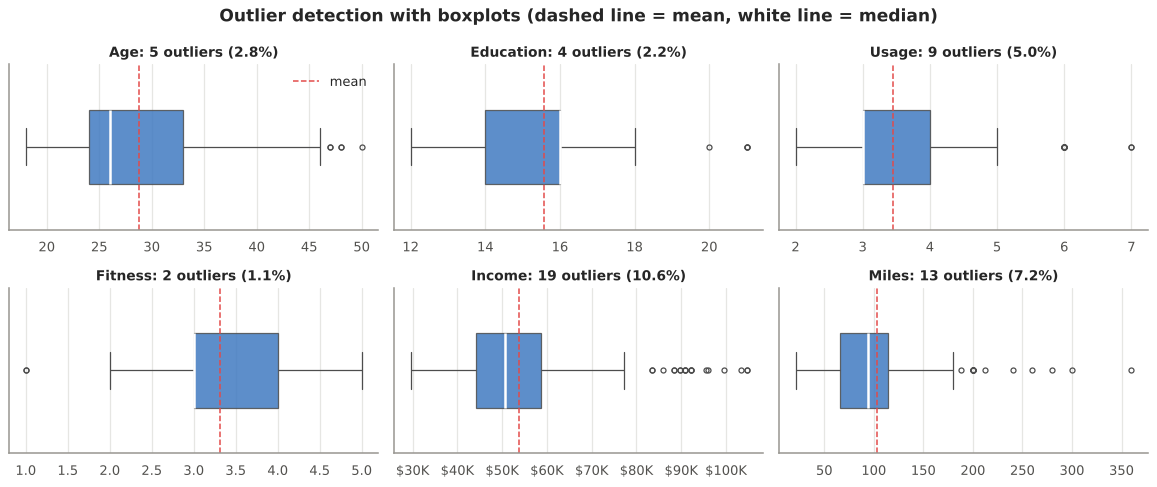

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(x=df[c], ax=ax, color="#2a78d6", width=0.45, fliersize=4,
                boxprops=dict(alpha=0.85), medianprops=dict(color="white", lw=2))
    ax.axvline(df[c].mean(), color="#e34948", ls="--", lw=1.2, label="mean")
    ax.set_title(f"{c}: {int(out.loc[c, 'n outliers'])} outliers ({out.loc[c, '% outliers']:.1f}%)")
    ax.set_xlabel("")
    if c == "Income":
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:.0f}K"))
axes[0, 0].legend(loc="upper right", frameon=False)
fig.suptitle("Outlier detection with boxplots (dashed line = mean, white line = median)", fontweight="bold")
fig.tight_layout(); save(fig, "01_outlier_boxplots"); plt.show()

**Observations**
* **Income** (19 outliers, 10.6%) and **Miles** (13, 7.2%) have the most outliers, all on the **high side**. Their means are 6.2% and 9.8% above their medians.
* **Age** has 5 high outliers (47 to 50 years). **Usage** has 9 (6 to 7 days a week). **Education** has 4 (20 to 21 years). **Fitness** has 2 (rating 1).
* **Are these errors? No.** They are real, plausible customers (a \$100K earner, a runner doing 300 miles a week). Section 5 shows that **almost all of them are KP781 buyers**, so they are the signal that defines the premium segment.
* **Decision:** keep every record for the analysis. For robustness we also show what clipping at the 5th to 95th percentile does to the mean.

In [16]:
clipped = df[num_cols].apply(lambda s: s.clip(s.quantile(0.05), s.quantile(0.95)))
pd.DataFrame({"mean (raw)": df[num_cols].mean(), "mean (5-95% clipped)": clipped.mean(),
              "median": df[num_cols].median()}).round(1).T

,Age,Education,Usage,Fitness,Income,Miles
mean (raw),28.8,15.6,3.5,3.3,53719.6,103.2
mean (5-95% clipped),28.6,15.6,3.4,3.3,53477.1,101.1
median,26.0,16.0,3.0,3.0,50596.5,94.0


Clipping pulls the means of Income (\$53.7K to \$53.5K) and Miles (103 to 101) towards their medians, but they stay well above them because the skew is in the bulk of the data and not only in a few points. The **median is the safer "typical customer" figure** for these two columns, so the profiles below use medians.

## 4. Visual analysis: univariate

### 4.1 Continuous variables: histogram + KDE (distplot)

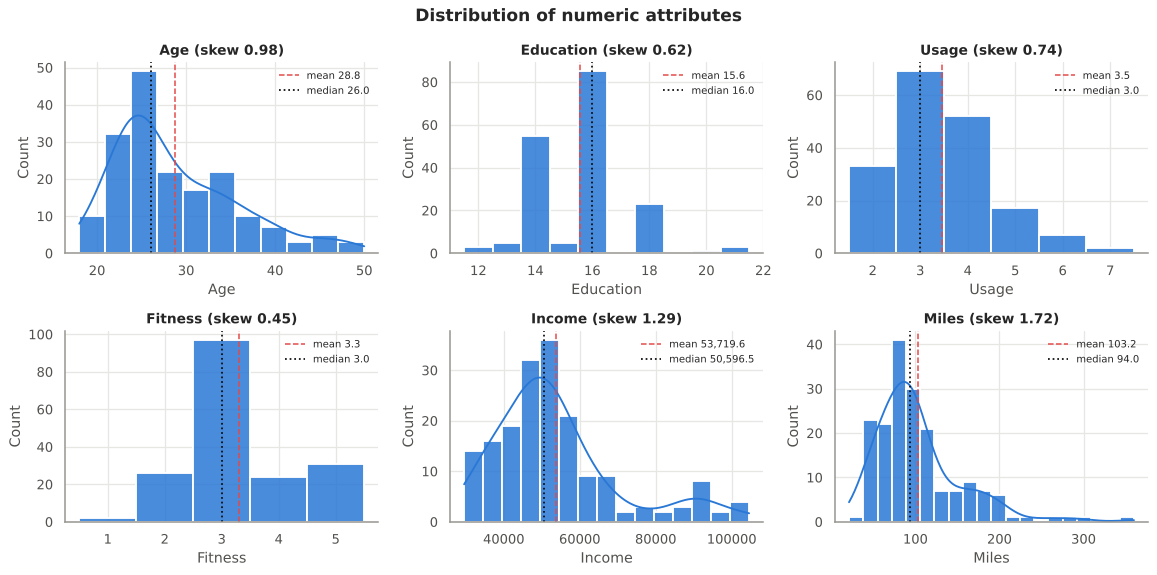

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.flat, num_cols):
    discrete = c in ["Usage", "Fitness", "Education"]
    sns.histplot(df[c], ax=ax, kde=not discrete, discrete=discrete, color="#2a78d6",
                 edgecolor="white", linewidth=1.5, alpha=0.85)
    ax.axvline(df[c].mean(), color="#e34948", ls="--", lw=1.2, label=f"mean {df[c].mean():,.1f}")
    ax.axvline(df[c].median(), color="#0b0b0b", ls=":", lw=1.4, label=f"median {df[c].median():,.1f}")
    ax.set_title(f"{c} (skew {df[c].skew():.2f})"); ax.legend(frameon=False, fontsize=8)
fig.suptitle("Distribution of numeric attributes", fontweight="bold")
fig.tight_layout(); save(fig, "02_numeric_distributions"); plt.show()

**Observations**
* **Age:** right-skewed (skew 0.98). Most buyers are 23 to 33. Buyers above 40 are rare, so treadmills mostly sell to **young adults**.
* **Income:** right-skewed (1.29) and slightly **bimodal**: a big block at \$40 to 60K and a second small hump at \$85 to 105K. That second hump is the KP781 market.
* **Miles:** right-skewed (1.72). A peak around 85 to 95 miles and a long tail up to 360 (serious runners).
* **Education:** clusters at 14, 16 and 18 years (school and degree milestones).
* **Usage:** mode is 3 days a week. **Fitness:** mode is 3/5. Both have small upper tails (Usage 5 to 7, Fitness 5) that, as we will see, belong to KP781 buyers.

### 4.2 Categorical variables: countplots

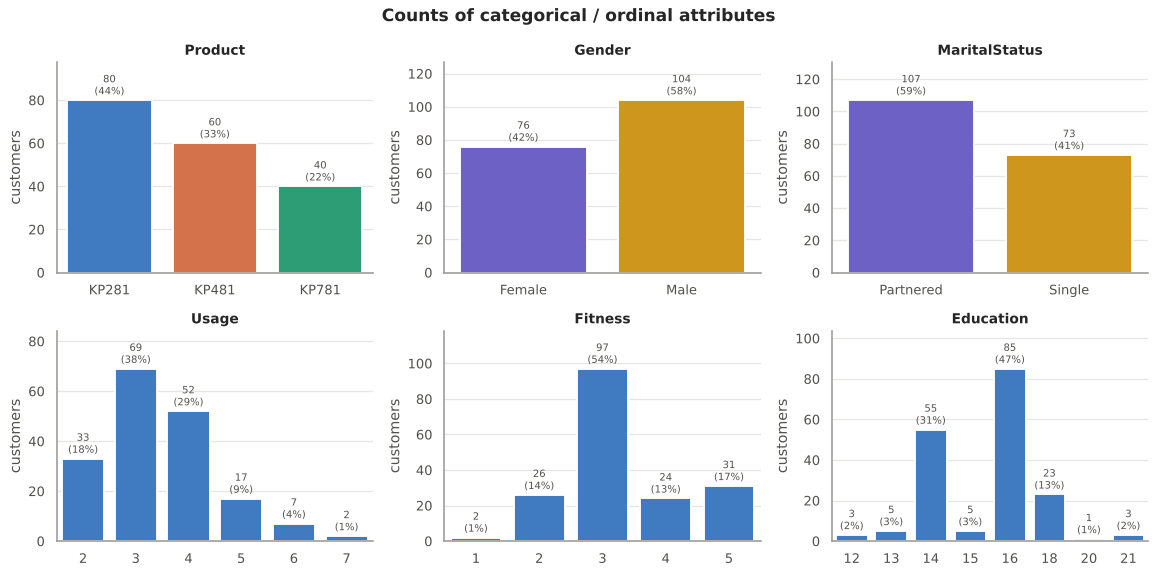

In [18]:
def label_bars(ax, total=None):
    total = total or sum(p.get_height() for p in ax.patches)
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(f"{int(h)}\n({h/total:.0%})", (p.get_x() + p.get_width() / 2, h), ha="center", va="bottom",
                        fontsize=8, color="#52514e", xytext=(0, 2), textcoords="offset points")
    ax.margins(y=0.22)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
specs = [("Product", PROD_PAL), ("Gender", BIN_PAL), ("MaritalStatus", BIN_PAL),
         ("Usage", None), ("Fitness", None), ("Education", None)]
for ax, (c, pal) in zip(axes.flat, specs):
    if pal is None:
        sns.countplot(x=df[c], ax=ax, color="#2a78d6", edgecolor="white", linewidth=1.5)
    else:
        sns.countplot(x=df[c], ax=ax, hue=df[c], palette=pal, legend=False, dodge=False, edgecolor="white", linewidth=1.5)
    label_bars(ax, len(df)); ax.set_title(c); ax.set_ylabel("customers"); ax.set_xlabel("")
fig.suptitle("Counts of categorical / ordinal attributes", fontweight="bold")
fig.tight_layout(); save(fig, "03_categorical_counts"); plt.show()

**Observations**
* **Product:** KP281 (44%) > KP481 (33%) > KP781 (22%). Demand falls as the price rises.
* **Gender:** 58% male, 42% female.
* **Marital status:** 59% partnered, 41% single. Treadmills are often a **household purchase**.
* **Usage:** 3 days (38%) and 4 days (29%) are most common. **Fitness:** 3/5 (54%) dominates, then 5/5 (17%), 2/5 and 4/5 (13 to 14%).
* **Education:** 16 years (47%) and 14 years (31%). Customers are mostly graduates.

## 5. Visual analysis: bivariate (does the feature affect the product purchased?)

### 5.1 Categorical features vs Product

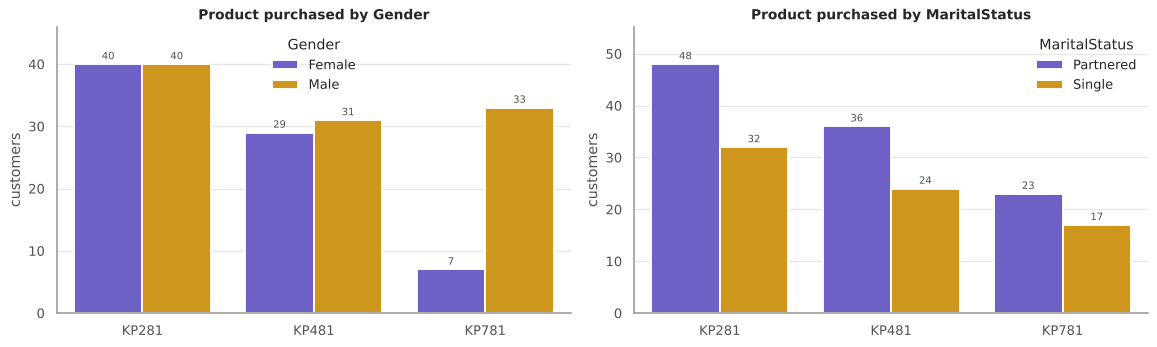

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["Gender", "MaritalStatus"]):
    sns.countplot(data=df, x="Product", hue=c, palette=BIN_PAL, ax=ax, edgecolor="white", linewidth=1.5)
    for cont in ax.containers:
        ax.bar_label(cont, fontsize=8, color="#52514e", padding=2)
    ax.set_title(f"Product purchased by {c}"); ax.set_xlabel(""); ax.set_ylabel("customers")
    ax.legend(title=c, frameon=False); ax.margins(y=0.15)
fig.tight_layout(); save(fig, "04_product_by_gender_marital"); plt.show()

**Observations**
* **Gender matters, but only at the top end.** KP281 is split evenly (40 M / 40 F) and KP481 nearly so (31 / 29), but **KP781 is 33 M vs 7 F**. Only 9% of women chose the KP781, against 32% of men.
* **Marital status barely matters.** Partnered buyers outnumber single buyers in every product in about the same 60:40 ratio, so the product mix is almost identical (KP781: 21.5% of partnered vs 23.3% of single buyers).

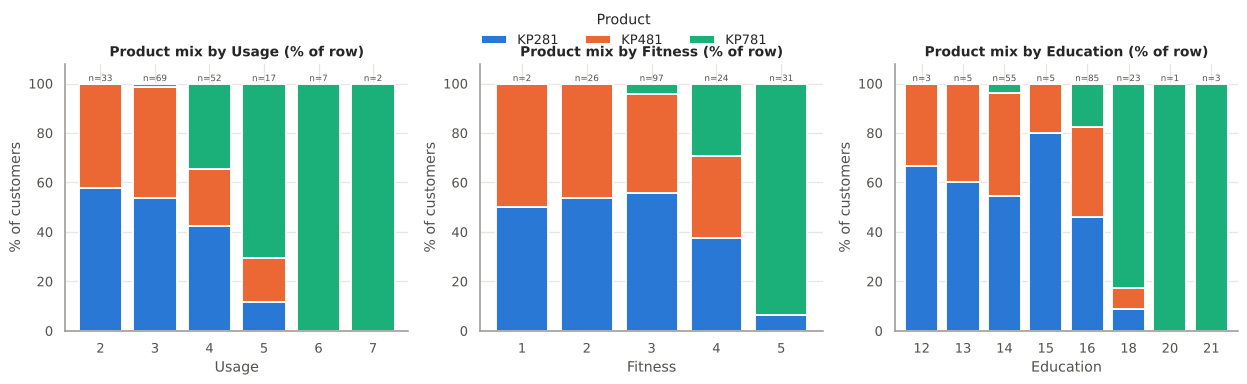

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Usage", "Fitness", "Education"]):
    ct = pd.crosstab(df[c], df["Product"], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=ax, color=[PROD_PAL[p] for p in PRODUCTS], edgecolor="white", linewidth=1.5, width=0.8)
    for i, n in enumerate(df[c].value_counts().sort_index()):
        ax.text(i, 101, f"n={n}", ha="center", fontsize=7, color="#52514e")
    ax.set_title(f"Product mix by {c} (% of row)"); ax.set_ylabel("% of customers"); ax.set_xlabel(c)
    ax.set_ylim(0, 108); ax.tick_params(axis="x", rotation=0); ax.legend_.remove()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="Product", frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout(); save(fig, "05_product_mix_ordinal"); plt.show()

**Observations**
* **Usage:** nobody planning 2 days chose the KP781 and only 1 of 69 planning 3 days did. At **5 days, 71%** chose it, and at **6 to 7 days, 100%** did.
* **Fitness:** customers rating themselves 1 to 3 almost never buy the KP781 (4 of 125). At **fitness 5, 94% buy the KP781** (29 of 31).
* **Education:** with 18 or more years of education, **85% buy the KP781** (23 of 27). At 16 years or fewer, the KP281 and KP481 dominate.
* Usage, fitness and education all have a **strong, step-like effect** on choosing the premium model.

### 5.2 Numeric features vs Product: boxplots

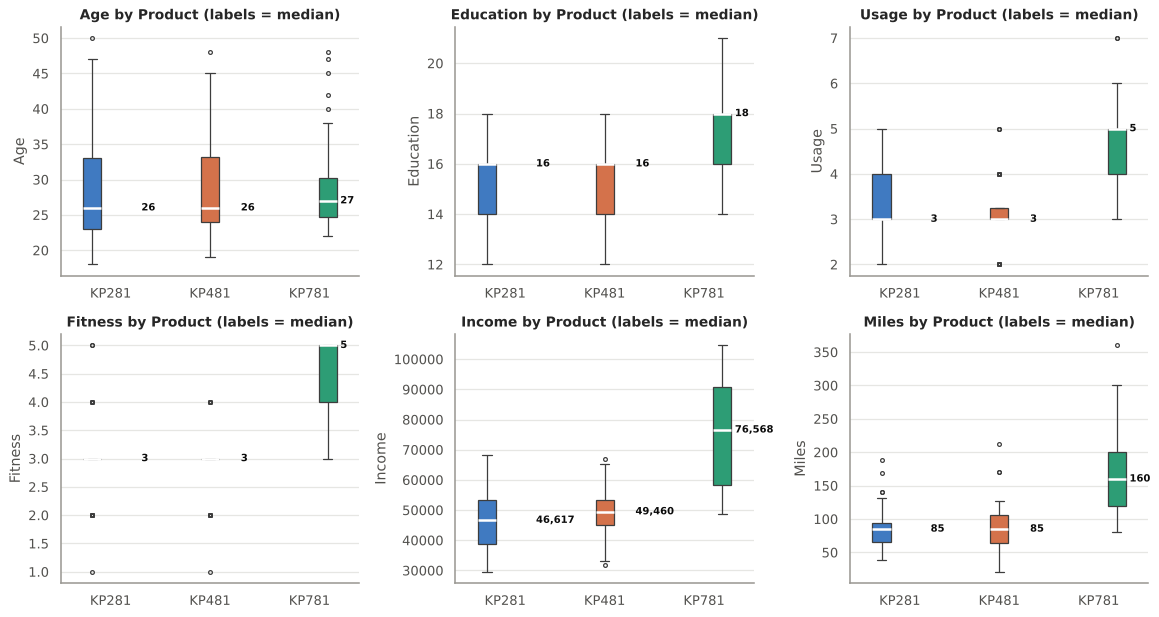

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="Product", y=c, hue="Product", palette=PROD_PAL, legend=False, ax=ax, width=0.55,
                fliersize=3, medianprops=dict(color="white", lw=2))
    for i, p in enumerate(PRODUCTS):
        m = df.loc[df.Product == p, c].median()
        ax.text(i + 0.31, m, f"{m:,.0f}", fontsize=8, va="center", ha="left", color="#0b0b0b", fontweight="bold")
    ax.set_title(f"{c} by Product (labels = median)"); ax.set_xlabel("")
fig.tight_layout(); save(fig, "06_numeric_by_product_boxplots"); plt.show()

**Observations**
* **Age:** medians of 26, 26 and 27. Age does **not** separate the products, but KP781 buyers sit in a narrower 25 to 30 core band (IQR).
* **Education:** median 16 for KP281/KP481 vs **18 for KP781**.
* **Usage:** median 3 vs **5** days a week. **Fitness:** median 3 vs **5**.
* **Income:** medians of \$46.6K / \$49.5K / **\$76.6K**. The KP781 box hardly overlaps the others. The "outliers" in the overall Income boxplot are simply KP781 buyers.
* **Miles:** medians of 85 / 85 / **160**. Again, the overall outliers are KP781 runners.
* **KP281 vs KP481:** the boxes overlap almost completely. Income is slightly higher for KP481 (+\$2.9K median). Their buyers are hard to tell apart.

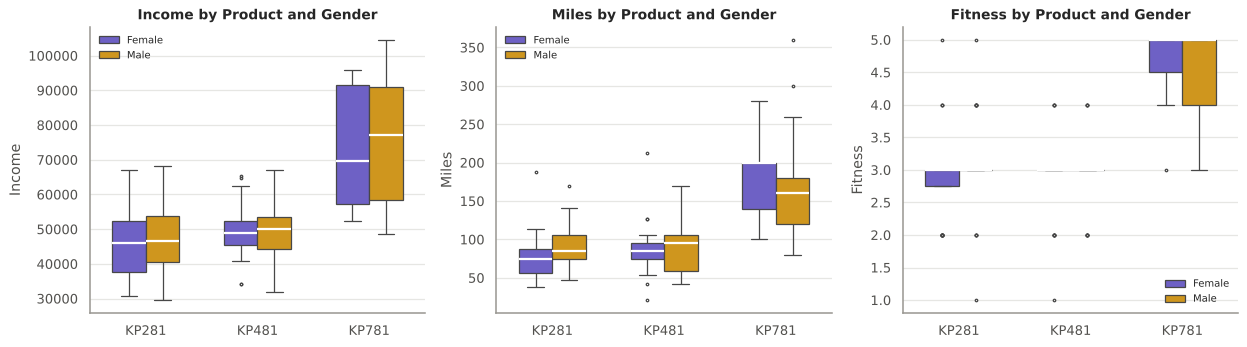

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Income", "Miles", "Fitness"]):
    sns.boxplot(data=df, x="Product", y=c, hue="Gender", palette=BIN_PAL, ax=ax, width=0.6, fliersize=2,
                medianprops=dict(color="white", lw=1.8))
    ax.set_title(f"{c} by Product and Gender"); ax.set_xlabel(""); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "07_numeric_by_product_gender"); plt.show()

**Observations**
* Within each product, men and women have **very similar income and fitness**. The women who do buy the KP781 are just as fit (4.6 avg) and wealthy (\$73.6K avg) as the men, and they plan **more** miles (180 vs 164).
* So the KP781 gender gap is **not** explained by income or fitness. It looks like a **marketing and awareness gap**, which Aerofit can act on.

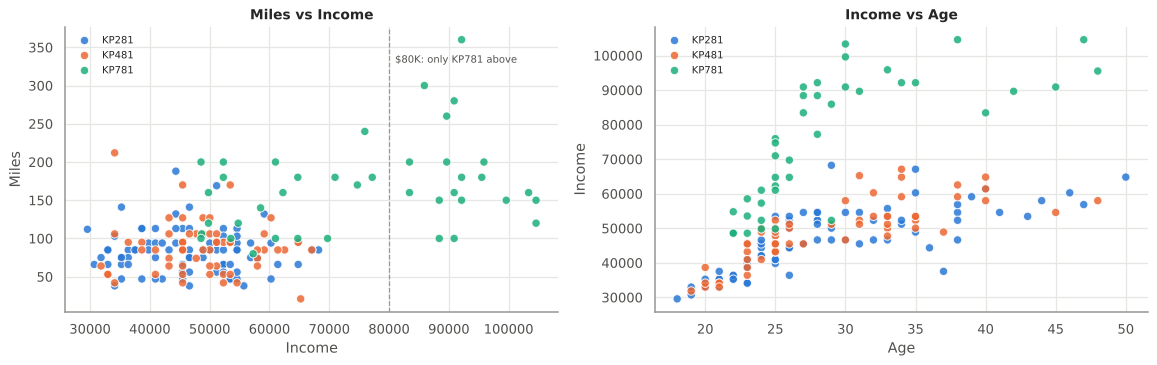

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (x, y) in zip(axes, [("Income", "Miles"), ("Age", "Income")]):
    sns.scatterplot(data=df, x=x, y=y, hue="Product", palette=PROD_PAL, ax=ax, s=45, alpha=0.85, edgecolor="white", linewidth=0.8)
    ax.set_title(f"{y} vs {x}"); ax.legend(frameon=False, fontsize=8)
axes[0].axvline(80_000, color="#9a9893", ls="--", lw=1); axes[0].text(81_000, 330, "$80K: only KP781 above", fontsize=8, color="#52514e")
fig.tight_layout(); save(fig, "08_scatter_income_miles_age"); plt.show()

**Observations**
* **Income vs Miles:** the KP781 (aqua) occupies the upper-right corner. **Every customer earning more than \$80K bought the KP781.** Under \$40K, nobody did.
* **Age vs Income:** income rises with age (r = 0.51). At any given age, KP781 buyers are the higher earners. Age alone does not decide the product, but income at that age does.

## 6. Correlation: heatmap & pairplot

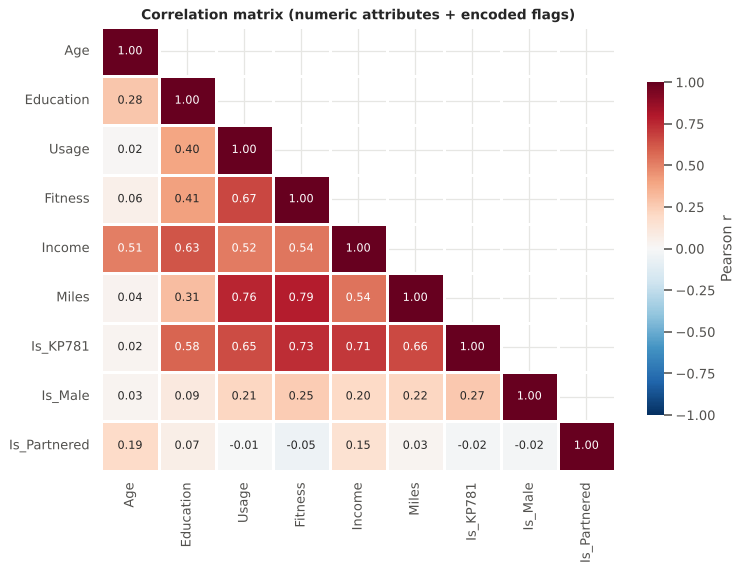

In [24]:
corr_df = df[num_cols].copy()
corr_df["Is_KP781"] = (df["Product"] == "KP781").astype(int)
corr_df["Is_Male"] = (df["Gender"] == "Male").astype(int)
corr_df["Is_Partnered"] = (df["MaritalStatus"] == "Partnered").astype(int)
corr = corr_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.75, "label": "Pearson r"}, ax=ax, annot_kws={"size": 9})
ax.set_title("Correlation matrix (numeric attributes + encoded flags)")
fig.tight_layout(); save(fig, "09_correlation_heatmap"); plt.show()

**Observations**
* **Strong positive:** Fitness & Miles (0.79), Usage & Miles (0.76), Usage & Fitness (0.67). Fitter people plan to run more often and further, which is the "athlete" cluster.
* **Moderate:** Income & Education (0.63), Income & Fitness/Usage/Miles (0.52 to 0.54), Income & Age (0.51).
* **Buying the KP781** correlates most with **Fitness (0.73)**, Income (0.71), Miles (0.66), Usage (0.65) and Education (0.58), and hardly at all with Age (0.02) or marital status (-0.02).
* **Age** is almost uncorrelated with Usage, Fitness and Miles (|r| ≤ 0.06). Older buyers are not less active.
* Being male correlates weakly with KP781 (0.27), consistent with the gender gap seen earlier.

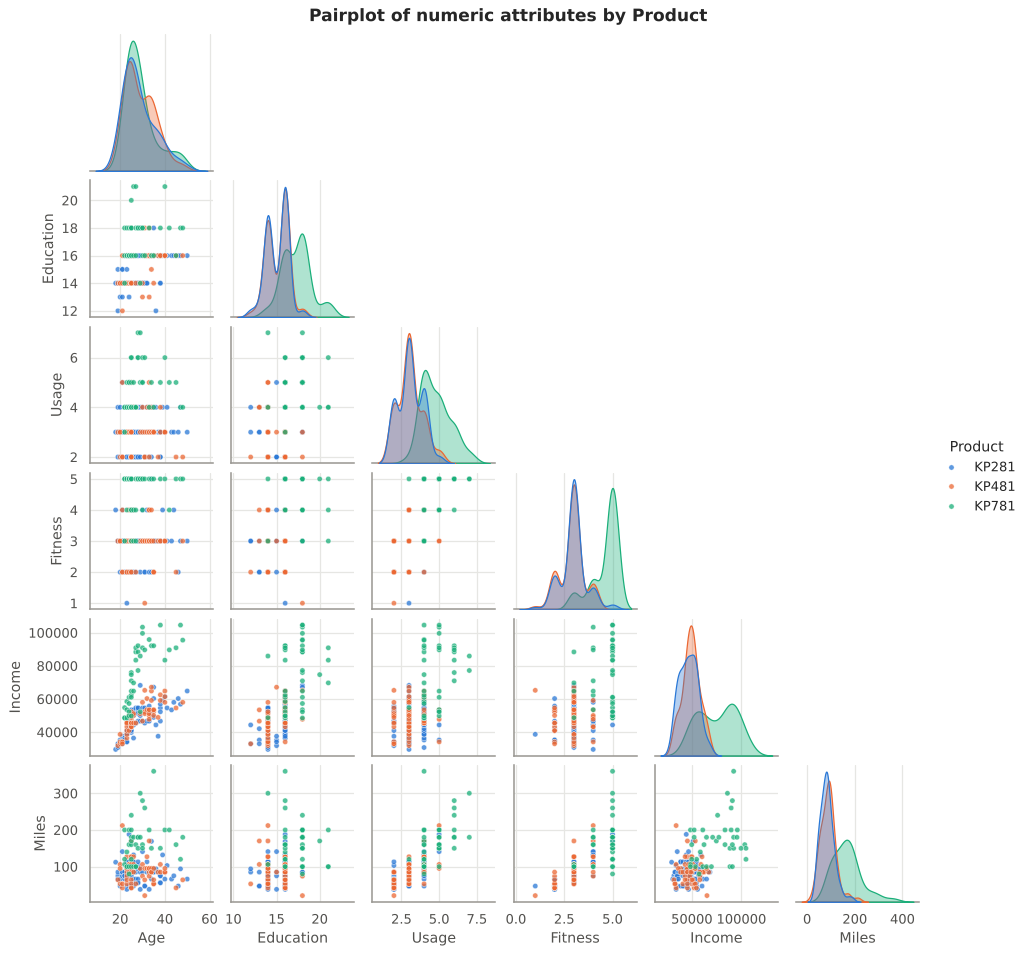

In [25]:
g = sns.pairplot(df[num_cols + ["Product"]], hue="Product", palette=PROD_PAL, corner=True, height=1.75,
                 plot_kws=dict(s=18, alpha=0.75, edgecolor="white", linewidth=0.4), diag_kind="kde",
                 diag_kws=dict(common_norm=False, fill=True, alpha=0.35))
g.figure.suptitle("Pairplot of numeric attributes by Product", fontweight="bold", y=1.01)
save(g.figure, "10_pairplot"); plt.show()

**Observations**
* On the diagonals (KDEs), **KP281 and KP481 overlap almost perfectly** on every attribute, while **KP781 shifts right** on Education, Usage, Fitness, Income and Miles. Age is the only attribute where all three overlap.
* The off-diagonal scatters show the KP781 forming a separate cloud in any pair that combines Income, Fitness, Usage or Miles. These four are the **best predictors** of a premium purchase.

## 7. Probability: marginal, joint & conditional

Notation: *P(A)* is a **marginal** probability, *P(A ∩ B)* is a **joint** probability and *P(A | B) = P(A ∩ B) / P(B)* is a **conditional** probability.
All probabilities are estimated from the 180 purchases using `pd.crosstab`.

### 7.1 Marginal probability of each product

In [26]:
marg = pd.DataFrame({"customers": df["Product"].value_counts(sort=False),
                     "P(Product)": df["Product"].value_counts(normalize=True, sort=False)})
marg.loc["Total"] = marg.sum()
marg.style.format({"customers": "{:.0f}", "P(Product)": "{:.1%}"})

,customers,P(Product)
Product,,
KP281,80,44.4%
KP481,60,33.3%
KP781,40,22.2%
Total,180,100.0%


**P(KP281) = 44.4%, P(KP481) = 33.3%, P(KP781) = 22.2%.** If we know nothing about a walk-in customer, the KP281 is the most likely sale. The probabilities below show how knowing a little about the customer changes these odds.

In [27]:
def prob_tables(col):
    counts = pd.crosstab(df[col], df["Product"], margins=True, margins_name="Total")
    joint = pd.crosstab(df[col], df["Product"], normalize="all", margins=True, margins_name="Total")
    p_prod_given = pd.crosstab(df[col], df["Product"], normalize="index")          # P(Product | col)
    p_given_prod = pd.crosstab(df[col], df["Product"], normalize="columns")        # P(col | Product)
    return counts, joint, p_prod_given, p_given_prod

def show(col):
    counts, joint, ppg, pgp = prob_tables(col)
    from IPython.display import display, HTML
    display(HTML(f"<b>Two-way contingency table (counts): {col} x Product</b>")); display(counts)
    display(HTML(f"<b>Joint & marginal probabilities: P({col} ∩ Product). Margins = marginal probabilities</b>"))
    display(joint.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None, subset=(joint.index[:-1], joint.columns[:-1])))
    display(HTML(f"<b>Conditional: P(Product | {col}). Rows sum to 100%</b>"))
    display(ppg.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))
    display(HTML(f"<b>Conditional: P({col} | Product). Columns sum to 100%</b>"))
    display(pgp.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

### 7.2 Gender × Product

In [28]:
show("Gender")

Product,KP281,KP481,KP781,Total
Gender,,,,
Female,40,29,7,76
Male,40,31,33,104
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
Gender,,,,
Female,22.2%,16.1%,3.9%,42.2%
Male,22.2%,17.2%,18.3%,57.8%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
Gender,,,
Female,52.6%,38.2%,9.2%
Male,38.5%,29.8%,31.7%


Product,KP281,KP481,KP781
Gender,,,
Female,50.0%,48.3%,17.5%
Male,50.0%,51.7%,82.5%


In [29]:
c, j, ppg, pgp = prob_tables("Gender")
print(f"P(Male)                 = {j.loc['Male','Total']:.3f}")
print(f"P(Male ∩ KP781)         = {j.loc['Male','KP781']:.3f}")
print(f"P(KP781 | Male)         = P(Male ∩ KP781) / P(Male) = {j.loc['Male','KP781']:.3f} / {j.loc['Male','Total']:.3f} = {ppg.loc['Male','KP781']:.3f}")
print(f"P(KP781 | Female)       = {ppg.loc['Female','KP781']:.3f}")
print(f"P(Female | KP281)       = {pgp.loc['Female','KP281']:.3f}")
print(f"P(Male | KP781)         = {pgp.loc['Male','KP781']:.3f}")
# Bayes check: P(Male | KP781) = P(KP781 | Male) * P(Male) / P(KP781)
print(f"Bayes check P(Male|KP781) = {ppg.loc['Male','KP781'] * j.loc['Male','Total'] / j.loc['Total','KP781']:.3f}")

P(Male)                 = 0.578
P(Male ∩ KP781)         = 0.183
P(KP781 | Male)         = P(Male ∩ KP781) / P(Male) = 0.183 / 0.578 = 0.317
P(KP781 | Female)       = 0.092
P(Female | KP281)       = 0.500
P(Male | KP781)         = 0.825
Bayes check P(Male|KP781) = 0.825


**Insights: Gender**
* **P(KP781 | Male) = 31.7%** (33 / 104), which is **3.4×** **P(KP781 | Female) = 9.2%** (7 / 76).
* **P(KP281 | Female) = 52.6%**. More than half of female buyers choose the entry model, and 90.8% choose KP281 or KP481.
* **P(Male | KP781) = 82.5%**. The premium buyer is overwhelmingly male, while KP281 buyers are exactly 50/50.
* **Impact:** premium marketing is reaching only men. Female-focused KP781 campaigns (and fitness-led rather than "power"-led messaging) are a clear growth lever.

### 7.3 Marital status × Product

In [30]:
show("MaritalStatus")

Product,KP281,KP481,KP781,Total
MaritalStatus,,,,
Partnered,48,36,23,107
Single,32,24,17,73
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
MaritalStatus,,,,
Partnered,26.7%,20.0%,12.8%,59.4%
Single,17.8%,13.3%,9.4%,40.6%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
MaritalStatus,,,
Partnered,44.9%,33.6%,21.5%
Single,43.8%,32.9%,23.3%


Product,KP281,KP481,KP781
MaritalStatus,,,
Partnered,60.0%,60.0%,57.5%
Single,40.0%,40.0%,42.5%


**Insights: Marital status**
* P(Partnered) = 59.4%, P(Single) = 40.6%.
* **P(Product | Partnered) and P(Product | Single) are nearly identical**: KP281 44.9% vs 43.8%, KP481 33.6% vs 32.9%, KP781 21.5% vs 23.3%.
* **Impact:** marital status should **not** drive the recommendation. The high share of partnered buyers does support **"family / couple" messaging** to reach more households.

### 7.4 Age group × Product

In [31]:
show("AgeGroup")

Product,KP281,KP481,KP781,Total
AgeGroup,,,,
18-24,27,17,10,54
25-34,36,31,23,90
35-44,14,10,4,28
45-50,3,2,3,8
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
AgeGroup,,,,
18-24,15.0%,9.4%,5.6%,30.0%
25-34,20.0%,17.2%,12.8%,50.0%
35-44,7.8%,5.6%,2.2%,15.6%
45-50,1.7%,1.1%,1.7%,4.4%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
AgeGroup,,,
18-24,50.0%,31.5%,18.5%
25-34,40.0%,34.4%,25.6%
35-44,50.0%,35.7%,14.3%
45-50,37.5%,25.0%,37.5%


Product,KP281,KP481,KP781
AgeGroup,,,
18-24,33.8%,28.3%,25.0%
25-34,45.0%,51.7%,57.5%
35-44,17.5%,16.7%,10.0%
45-50,3.8%,3.3%,7.5%


**Insights: Age**
* **P(25-34) = 50%** and P(18-24) = 30%, so 80% of buyers are under 35.
* P(KP781 | 25-34) = 25.6% is the highest among the large groups. P(KP281 | 18-24) = 50%: students and early-career buyers prefer the entry model.
* The 45-50 group is tiny (n = 8), so its 37.5% KP781 share is not reliable.
* **Impact:** the core market is **18-34**. Age shifts the mix only modestly, so use it to choose **channels** (social media, college and corporate tie-ups), not to pick the model.

### 7.5 Income band × Product

In [32]:
show("IncomeBand")

Product,KP281,KP481,KP781,Total
IncomeBand,,,,
<40K,23,9,0,32
40-60K,51,44,11,106
60-80K,6,7,10,23
80K+,0,0,19,19
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
IncomeBand,,,,
<40K,12.8%,5.0%,0.0%,17.8%
40-60K,28.3%,24.4%,6.1%,58.9%
60-80K,3.3%,3.9%,5.6%,12.8%
80K+,0.0%,0.0%,10.6%,10.6%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
IncomeBand,,,
<40K,71.9%,28.1%,0.0%
40-60K,48.1%,41.5%,10.4%
60-80K,26.1%,30.4%,43.5%
80K+,0.0%,0.0%,100.0%


Product,KP281,KP481,KP781
IncomeBand,,,
<40K,28.7%,15.0%,0.0%
40-60K,63.7%,73.3%,27.5%
60-80K,7.5%,11.7%,25.0%
80K+,0.0%,0.0%,47.5%


**Insights: Income** (the strongest single driver)
* **P(KP781 | Income > \$80K) = 100%** and **P(KP781 | Income < \$40K) = 0%**.
* P(KP281 | < \$40K) = 71.9%. For \$40-60K the choice is mostly KP281 (48.1%) or KP481 (41.5%). For \$60-80K the KP781 leads (43.5%).
* **P(Income ≤ \$60K | KP281) = 92.5%** and **P(Income > \$60K | KP781) = 72.5%**.
* **Impact:** income is the best sorting question. Offer **EMI / financing** to \$40-80K customers who show "athlete" signals so that the KP781 is within reach.

### 7.6 Fitness level × Product

In [33]:
show("FitnessLevel")

Product,KP281,KP481,KP781,Total
FitnessLevel,,,,
Low (1-2),15,13,0,28
Average (3),54,39,4,97
High (4-5),11,8,36,55
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
FitnessLevel,,,,
Low (1-2),8.3%,7.2%,0.0%,15.6%
Average (3),30.0%,21.7%,2.2%,53.9%
High (4-5),6.1%,4.4%,20.0%,30.6%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
FitnessLevel,,,
Low (1-2),53.6%,46.4%,0.0%
Average (3),55.7%,40.2%,4.1%
High (4-5),20.0%,14.5%,65.5%


Product,KP281,KP481,KP781
FitnessLevel,,,
Low (1-2),18.8%,21.7%,0.0%
Average (3),67.5%,65.0%,10.0%
High (4-5),13.8%,13.3%,90.0%


**Insights: Fitness**
* **P(KP781 | Fitness 4-5) = 65.5%**, P(KP781 | Fitness 3) = 4.1%, P(KP781 | Fitness 1-2) = 0%.
* **P(Fitness 4-5 | KP781) = 90%**, against only about 13 to 14% for KP281/KP481 buyers.
* **Impact:** a quick in-store question ("How would you rate your fitness, 1 to 5?") is a powerful recommendation tool.

### 7.7 Planned usage × Product

In [34]:
show("UsageLevel")

Product,KP281,KP481,KP781,Total
UsageLevel,,,,
Light (2-3),56,45,1,102
Moderate (4),22,12,18,52
Heavy (5-7),2,3,21,26
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
UsageLevel,,,,
Light (2-3),31.1%,25.0%,0.6%,56.7%
Moderate (4),12.2%,6.7%,10.0%,28.9%
Heavy (5-7),1.1%,1.7%,11.7%,14.4%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
UsageLevel,,,
Light (2-3),54.9%,44.1%,1.0%
Moderate (4),42.3%,23.1%,34.6%
Heavy (5-7),7.7%,11.5%,80.8%


Product,KP281,KP481,KP781
UsageLevel,,,
Light (2-3),70.0%,75.0%,2.5%
Moderate (4),27.5%,20.0%,45.0%
Heavy (5-7),2.5%,5.0%,52.5%


**Insights: Usage**
* **P(KP781 | Heavy 5-7 days) = 80.8%** and P(KP781 | Light 2-3 days) = 1%.
* P(Light 2-3 days | KP281) = 70% and P(Light | KP481) = 75%. Entry and mid buyers are casual users.
* **Impact:** "How many days a week will you run?" is the second key qualifying question.

### 7.8 Expected miles × Product

In [35]:
show("MilesBand")

Product,KP281,KP481,KP781,Total
MilesBand,,,,
<=75,38,21,0,59
76-150,40,36,17,93
150+,2,3,23,28
Total,80,60,40,180


Product,KP281,KP481,KP781,Total
MilesBand,,,,
<=75,21.1%,11.7%,0.0%,32.8%
76-150,22.2%,20.0%,9.4%,51.7%
150+,1.1%,1.7%,12.8%,15.6%
Total,44.4%,33.3%,22.2%,100.0%


Product,KP281,KP481,KP781
MilesBand,,,
<=75,64.4%,35.6%,0.0%
76-150,43.0%,38.7%,18.3%
150+,7.1%,10.7%,82.1%


Product,KP281,KP481,KP781
MilesBand,,,
<=75,47.5%,35.0%,0.0%
76-150,50.0%,60.0%,42.5%
150+,2.5%,5.0%,57.5%


**Insights: Miles**
* **P(KP781 | Miles > 150) = 82.1%**, while P(KP781 | Miles ≤ 75) = 0%.
* 97.5% of KP281 buyers plan 150 miles a week or less (47.5% plan 75 or less). The entry model easily handles their load.

### 7.9 Combined segments: Gender × Marital status

In [36]:
seg = pd.crosstab([df["Gender"], df["MaritalStatus"]], df["Product"], normalize="index")
seg["n"] = df.groupby(["Gender", "MaritalStatus"], observed=True).size()
seg.style.format({p: "{:.1%}" for p in PRODUCTS} | {"n": "{:.0f}"}).background_gradient(cmap="Blues", subset=PRODUCTS, axis=None)

**Insights**
* **Partnered women** are the most entry-level segment: **P(KP281 | Female, Partnered) = 58.7%**.
* **Single women** lean to the **KP481 (46.7%)**, the highest KP481 share of any segment.
* **Men** (single or partnered) buy the KP781 about 31 to 33% of the time.

### 7.10 Probability summary chart

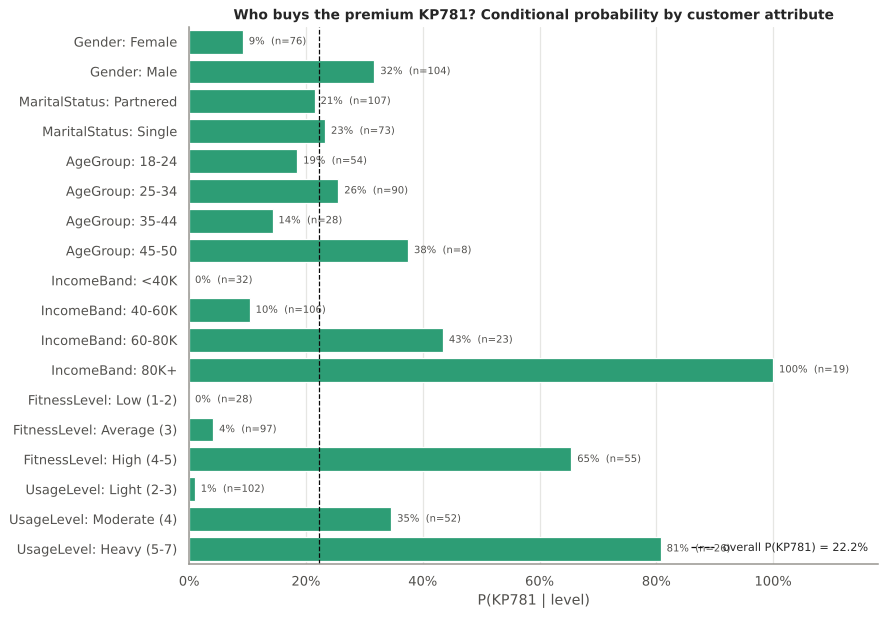

In [37]:
rows = []
for col in ["Gender", "MaritalStatus", "AgeGroup", "IncomeBand", "FitnessLevel", "UsageLevel"]:
    t = pd.crosstab(df[col], df["Product"], normalize="index")
    for lvl in t.index:
        rows.append({"feature": col, "level": f"{col}: {lvl}", "P(KP781 | level)": t.loc[lvl, "KP781"],
                     "n": (df[col] == lvl).sum()})
p781 = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=p781, y="level", x="P(KP781 | level)", color="#1baf7a", ax=ax, edgecolor="white")
ax.axvline(df["Product"].eq("KP781").mean(), color="#0b0b0b", ls="--", lw=1, label="overall P(KP781) = 22.2%")
ax.legend(loc="lower right", frameon=False, fontsize=9)
for i, r in p781.iterrows():
    ax.text(r["P(KP781 | level)"] + 0.01, i, f"{r['P(KP781 | level)']:.0%}  (n={r['n']})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.18); ax.set_ylabel(""); ax.set_title("Who buys the premium KP781? Conditional probability by customer attribute")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); save(fig, "11_p_kp781_by_attribute"); plt.show()

The chart ranks the attributes by how much they raise or lower the chance of a **KP781** sale against the 22.2% baseline. **Income > \$80K (100%), heavy usage (81%) and high fitness (66%)** are the strongest signals. Marital status and age barely move it.

### 7.11 Are the differences statistically significant? (Chi-square test of independence)
A quick check that the patterns are unlikely to be due to chance (H₀: the attribute and the product purchased are independent; α = 0.05).

In [38]:
res = []
for col in ["Gender", "MaritalStatus", "AgeGroup", "IncomeBand", "FitnessLevel", "UsageLevel", "MilesBand"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df["Product"]))
    res.append({"attribute": col, "chi2": chi2, "dof": dof, "p-value": p,
                "depends on product? (α=0.05)": "Yes" if p < 0.05 else "No"})
pd.DataFrame(res).set_index("attribute").style.format({"chi2": "{:.1f}", "p-value": "{:.2e}"})

,chi2,dof,p-value,depends on product? (α=0.05)
attribute,,,,
Gender,12.9,2,1.56e-03,Yes
MaritalStatus,0.1,2,9.60e-01,No
AgeGroup,3.8,6,7.07e-01,No
IncomeBand,94.9,6,2.89e-18,Yes
FitnessLevel,86.1,4,8.92e-18,Yes
UsageLevel,83.8,4,2.75e-17,Yes
MilesBand,78.3,4,4.00e-16,Yes


* **Income, Fitness, Usage, Miles and Gender** are significantly associated with the product purchased (p < 0.05).
* **Marital status and Age group are not** (p > 0.05). This confirms the visual finding that they should not drive the recommendation.
* *(Some cells in the income, fitness and usage tables have small expected counts, so read their exact p-values loosely. The direction of the result is clear.)*

## 8. Customer profiling: categorization of users

In [39]:
def profile(g):
    return pd.Series({
        "Buyers": f"{len(g)} ({len(g)/len(df):.0%})",
        "Revenue": f"${len(g) * PRICE[g.name]:,.0f}",
        "Age (median, IQR)": f"{g.Age.median():.0f} ({g.Age.quantile(.25):.0f}-{g.Age.quantile(.75):.0f})",
        "Male share": f"{(g.Gender == 'Male').mean():.0%}",
        "Partnered share": f"{(g.MaritalStatus == 'Partnered').mean():.0%}",
        "Education (median yrs)": f"{g.Education.median():.0f}",
        "Income (median)": f"${g.Income.median():,.0f}",
        "Income range": f"${g.Income.min():,.0f} - ${g.Income.max():,.0f}",
        "Usage (median days/wk)": f"{g.Usage.median():.0f}",
        "Fitness (median /5)": f"{g.Fitness.median():.0f}",
        "Miles (median/wk)": f"{g.Miles.median():.0f}",
    })
profiles = df.groupby("Product", observed=True).apply(profile, include_groups=False).T
profiles

Product,KP281,KP481,KP781
Buyers,80 (44%),60 (33%),40 (22%)
Revenue,"$120,000","$105,000","$100,000"
"Age (median, IQR)",26 (23-33),26 (24-33),27 (25-30)
Male share,50%,52%,82%
Partnered share,60%,60%,57%
Education (median yrs),16,16,18
Income (median),"$46,617","$49,460","$76,568"
Income range,"$29,562 - $68,220","$31,836 - $67,083","$48,556 - $104,581"
Usage (median days/wk),3,3,5
Fitness (median /5),3,3,5


| | **KP281: "The Starter"** | **KP481: "The Progressing Runner"** | **KP781: "The Serious Athlete"** |
|---|---|---|---|
| Who | Young (core 23 to 33), **equal men and women**, 60% partnered | Young (core 24 to 33), **52% men**, the favourite of single women | Core 25 to 30, **82.5% men**, highly educated (18 yrs) |
| Money | Median **\$46.6K**, all ≤ \$68.2K | Median **\$49.5K**, all ≤ \$67.1K | Median **\$76.6K**, up to \$104.6K. **Every \$80K+ buyer** |
| Activity | 3 days/week, 85 miles, fitness 3 | 3 days/week, 85 miles, fitness 3 | **5 days/week, 160 miles, fitness 5** |
| Motivation | Getting started, staying healthy, budget-aware | Steady routine, wants a bit more than entry level | Training performance, wants advanced features |
| How to sell | Price, value, ease of use | Step-up benefits vs KP281, value for \$250 extra | Performance specs, durability, premium service |

**Quick recommendation guide for sales staff**
1. **Income > \$80K, or runs 5+ days a week, or fitness 5/5:** recommend the **KP781** (70 to 100% historical hit rate).
2. **Income < \$40K, or 2 to 3 days a week, or fitness ≤ 3:** recommend the **KP281** (with the KP481 as the step-up).
3. **Everyone in between (\$40 to 60K, moderate use):** show the **KP281 vs KP481** side by side and let the extra features justify the \$250.

## 9. Business insights

**Range & distribution of attributes**
* Buyers are **young** (18 to 50, median 26), **educated** (12 to 21 yrs, median 16), **middle-income** (\$29.6K to \$104.6K, median \$50.6K), and plan **moderate** use (2 to 7 days, median 3; 21 to 360 miles, median 94).
* Age, Income and Miles are **right-skewed**. Their high-side "outliers" are **genuine premium (KP781) customers**, not errors. There are no missing values and no duplicates.

**What drives the product choice**
1. **Income is the #1 driver.** KP281 → KP481 → KP781 tracks income (\$46.6K → \$49.5K → \$76.6K median). Above \$80K everyone bought the KP781; below \$40K nobody did.
2. **Fitness, usage and miles go together** (r = 0.67 to 0.79) and define the KP781 "athlete": fitness 5, 5 days a week, 160 miles.
3. **Gender matters only at the top.** P(KP781 | Male) = 31.7% vs P(KP781 | Female) = 9.2%. Women who do buy the KP781 are as fit and affluent as men, so the gap is about **reach and messaging, not ability to pay**.
4. **Marital status and age do not change the choice** (chi-square p > 0.05). They are useful for targeting channels, not for recommending models.
5. **KP281 and KP481 buyers are almost the same people.** The KP481's only differences are slightly higher income and more appeal to single women.

**Commercial picture**
* KP281 leads units (44%), but revenue is almost evenly split (37% / 32% / 31%). **One KP781 sale ≈ 1.7 KP281 sales**, so moving even a few customers up the range adds real revenue.

## 10. Recommendations (simple, actionable)

1. **Use a 3-question checklist in store and online:** *"How many days a week will you use it?", "How fit do you feel, 1 to 5?", "What budget are you comfortable with?"* Map the answers to the quick guide in Section 8.
2. **Market the KP781 to women.** Run campaigns with female athletes, women's running clubs and gyms. Show that the KP781 suits serious runners of any gender. Today only 7 of 76 female buyers chose it.
3. **Make the KP781 affordable for "athletes on a budget".** Offer no-cost EMI, trade-in or upgrade plans to customers earning \$40 to 80K who run 4+ days a week.
4. **Give the KP481 a clear identity.** Position it as "the treadmill you won't outgrow" for people building a routine (3 to 4 days a week). Bundle extras (a mat, a heart-rate strap, a 3-month training plan) so the \$250 step-up from the KP281 feels obvious.
5. **Keep the KP281 the go-to starter.** Lead with price, compact size and ease of use. Target students, first jobbers and couples (the largest group of buyers).
6. **Grow households and couples.** 59% of buyers are partnered. Run "fitness for two" offers and family profiles in the app.
7. **Upsell over time.** KP281 owners who start using it 4+ days a week are tomorrow's KP781 buyers. Follow up after 6 to 12 months with trade-in offers.
8. **Collect more data.** Purchase channel, region and the reason for buying would sharpen these profiles, and a larger sample would firm up the small groups (age 45+, women buying the KP781).